# Why the KYC pass rate is falling: analysis of KYC vendor check data

**Author:** Ekaterina Karpova · **Data:** `KYC_summary.csv`, `KYC_details.csv`

## Task
The share of users who successfully pass KYC (pass rate) is decreasing. We need to understand why and suggest what to do about it.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick

## 2. Loading the data
- `KYC_summary.csv`: the final decision for each user and the date.
- `KYC_details.csv`: decisions for each KYC vendor check, document type and country, year of birth.

We read `user_reference` as a string: it is an identifier, not a number.

In [2]:
summary = pd.read_csv('KYC_summary.csv', dtype={'user_reference': str})
details = pd.read_csv('KYC_details.csv', dtype={'user_reference': str})
# Mask user IDs consistently across both tables before any analysis or display.
all_ids = sorted(set(summary['user_reference'].dropna()) | set(details['user_reference'].dropna()))
id_map = {raw_id: f'user_{i:03d}' for i, raw_id in enumerate(all_ids, start=1)}
summary['user_reference'] = summary['user_reference'].map(id_map)
details['user_reference'] = details['user_reference'].map(id_map)
summary['date_'] = pd.to_datetime(summary['date_']).dt.tz_localize(None)

In [3]:
summary.head(3)

,date_,user_reference,decision_type
0,2023-07-25,user_002,PASSED
1,2023-07-25,user_007,PASSED
2,2023-07-25,user_004,PASSED


In [4]:
details.head(3)

,user_reference,decision_label,usability_decision,usability_decision_details,image_checks_decision,image_checks_decision_details,extraction_decision,extraction_decision_details,data_checks_decision,data_checks_decision_details,liveness_decision,liveness_decision_details,similarity_decision,similarity_decision_details,watchlist_screening_decision,data_type,data_sub_type,data_issuing_country,year_birth
0,user_002,PASSED,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,MATCH,PASSED,ID_CARD,ELECTORAL_ID,MEX,1980.0
1,user_007,PASSED,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,MATCH,PASSED,DRIVING_LICENSE,REGULAR_DRIVING_LICENSE,MEX,1973.0
2,user_004,PASSED,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,OK,PASSED,MATCH,PASSED,ID_CARD,NATIONAL_ID,MEX,1995.0


In [5]:
summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52075 entries, 0 to 52074
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date_           52075 non-null  datetime64[ns]
 1   user_reference  52075 non-null  object        
 2   decision_type   52075 non-null  object        
dtypes: datetime64[ns](1), object(2)
memory usage: 1.2+ MB


In [6]:
details.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52075 entries, 0 to 52074
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_reference                 52075 non-null  object 
 1   decision_label                 52075 non-null  object 
 2   usability_decision             52075 non-null  object 
 3   usability_decision_details     52075 non-null  object 
 4   image_checks_decision          52075 non-null  object 
 5   image_checks_decision_details  52075 non-null  object 
 6   extraction_decision            52075 non-null  object 
 7   extraction_decision_details    52075 non-null  object 
 8   data_checks_decision           52075 non-null  object 
 9   data_checks_decision_details   52075 non-null  object 
 10  liveness_decision              52075 non-null  object 
 11  liveness_decision_details      52075 non-null  object 
 12  similarity_decision            52075 non-null 

Summary has 52 075 rows with no missing values. Details has the same number of rows, with missing values in four columns: `watchlist_screening_decision`, `data_type`, `data_sub_type`, `year_birth`. The date is converted to datetime. pandas read the year of birth as `float64`.

## 3. Data quality checks
Before looking for the cause of the drop, let's make sure the data can be trusted.

### 3.1. Column overview

In [7]:
details.describe(include='object').T

,count,unique,top,freq
user_reference,52075,52075,user_006,1
decision_label,52075,5,PASSED,44816
usability_decision,52075,4,PASSED,49647
usability_decision_details,52075,15,OK,49646
image_checks_decision,52075,4,PASSED,47219
image_checks_decision_details,52075,15,OK,47220
extraction_decision,52075,3,PASSED,48164
extraction_decision_details,52075,3,OK,48165
data_checks_decision,52075,4,PASSED,47210
data_checks_decision_details,52075,5,OK,47211


- `user_reference`: the number of unique values equals the number of rows, so there are no duplicate users.
- Documents were issued in two countries (`data_issuing_country`), most often an ID_CARD.

`describe` shows only the number of unique values and the most frequent one. Let's look at the values of the categorical fields themselves:

In [8]:
def unique_values(frame, cols):
    '''Number of unique values and their list for each column.'''
    return pd.DataFrame({'unique': frame[cols].nunique(),
                         'values': [', '.join(sorted(frame[c].dropna().unique())) for c in cols]})

uniq = pd.concat([
    unique_values(details, [c for c in details.columns if c not in ('user_reference', 'year_birth')]),
    unique_values(summary, ['decision_type']).rename(index={'decision_type': 'decision_type (summary)'}),
])
with pd.option_context('display.max_colwidth', None):
    display(uniq)

,unique,values
decision_label,5,"APPROVED, OK, PASSED, REJECTED, WARNING"
usability_decision,4,"NOT_EXECUTED, PASSED, REJECTED, WARNING"
usability_decision_details,15,"BLURRED, DAMAGED_DOCUMENT, GLARE, LIVENESS_UNDETERMINED, MISSING_MANDATORY_DATAPOINTS, MISSING_PAGE, NOT_A_DOCUMENT, NOT_UPLOADED, OK, PART_OF_DOCUMENT_HIDDEN, PART_OF_DOCUMENT_MISSING, PASSED, PHOTOCOPY, TECHNICAL_ERROR, UNSUPPORTED_DOCUMENT_TYPE"
image_checks_decision,4,"NOT_EXECUTED, PASSED, PASSES, REJECTED"
image_checks_decision_details,15,"DIGITAL_COPY, FAKE, MANIPULATED_DOCUMENT, MANIPULATED_DOCUMENT_DOB, MANIPULATED_DOCUMENT_DOCUMENT_NUMBER, MANIPULATED_DOCUMENT_EXPIRY, MANIPULATED_DOCUMENT_NAME, MANIPULATED_DOCUMENT_PHOTO, MANIPULATED_DOCUMENT_SECURITY_CHECKS, MISMATCH_FRONT_BACK, OK, OTHER_REJECTION, PRECONDITION_NOT_FULFILLED, PUNCHED, TECHNICAL_ERROR"
extraction_decision,3,"NOT_EXECUTED, PASSED, PASSES"
extraction_decision_details,3,"OK, PRECONDITION_NOT_FULFILLED, TECHNICAL_ERROR"
data_checks_decision,4,"NOT_EXECUTED, PASSED, PASSES, REJECTED"
data_checks_decision_details,5,"MISMATCHING_DATAPOINTS, MISMATCH_HRZ_MRZ_DATA, OK, PRECONDITION_NOT_FULFILLED, TECHNICAL_ERROR"
liveness_decision,4,"NOT_EXECUTED, PASSED, REJECTED, WARNING"


The table shows four suspicious values:
- `PASSES` in `image_checks_decision`, `extraction_decision` and `data_checks_decision` (looks like a typo for `PASSED`);
- `OK` in `decision_label`, although there is no such final status in summary;
- `PASSED` among the `usability_decision_details` details, where the rest are reason codes;
- `OK` among the `similarity_decision_details` details, although there is a `MATCH` code.

In [9]:
STAGES = ['usability', 'image_checks', 'extraction', 'data_checks', 'liveness', 'similarity', 'watchlist_screening']

# 1. Rows with PASSES: decision and details for the same check
for s in STAGES:
    mask = details[f'{s}_decision'] == 'PASSES'
    if mask.any():
        display(details[mask])
        print(f'{s}: rows with PASSES {mask.sum()}, details: {details.loc[mask, f"{s}_decision_details"].value_counts().to_dict()}')

,user_reference,decision_label,usability_decision,usability_decision_details,image_checks_decision,image_checks_decision_details,extraction_decision,extraction_decision_details,data_checks_decision,data_checks_decision_details,liveness_decision,liveness_decision_details,similarity_decision,similarity_decision_details,watchlist_screening_decision,data_type,data_sub_type,data_issuing_country,year_birth
31819,user_003,PASSED,PASSED,OK,PASSES,OK,PASSES,OK,PASSES,OK,PASSED,OK,PASSED,MATCH,NaN,NaN,NaN,MEX,NaN


image_checks: rows with PASSES 1, details: {'OK': 1}


,user_reference,decision_label,usability_decision,usability_decision_details,image_checks_decision,image_checks_decision_details,extraction_decision,extraction_decision_details,data_checks_decision,data_checks_decision_details,liveness_decision,liveness_decision_details,similarity_decision,similarity_decision_details,watchlist_screening_decision,data_type,data_sub_type,data_issuing_country,year_birth
31819,user_003,PASSED,PASSED,OK,PASSES,OK,PASSES,OK,PASSES,OK,PASSED,OK,PASSED,MATCH,NaN,NaN,NaN,MEX,NaN


extraction: rows with PASSES 1, details: {'OK': 1}


,user_reference,decision_label,usability_decision,usability_decision_details,image_checks_decision,image_checks_decision_details,extraction_decision,extraction_decision_details,data_checks_decision,data_checks_decision_details,liveness_decision,liveness_decision_details,similarity_decision,similarity_decision_details,watchlist_screening_decision,data_type,data_sub_type,data_issuing_country,year_birth
31819,user_003,PASSED,PASSED,OK,PASSES,OK,PASSES,OK,PASSES,OK,PASSED,OK,PASSED,MATCH,NaN,NaN,NaN,MEX,NaN


data_checks: rows with PASSES 1, details: {'OK': 1}


`PASSES` appears in 1 row. Its details are `OK`, as for a passed check, so it is a typo for `PASSED`.

In [10]:
# 2. Which details passed usability and similarity checks have
pd.concat({
    'usability (decision PASSED)': details.loc[details['usability_decision'] == 'PASSED', 'usability_decision_details'].value_counts(),
    'similarity (decision PASSED)': details.loc[details['similarity_decision'] == 'PASSED', 'similarity_decision_details'].value_counts(),
}, names=['check', 'details']).rename('rows').to_frame()

rows
check                        details       
usability (decision PASSED)  OK       49646
                             PASSED       1
similarity (decision PASSED) MATCH    47917
                             OK           9

- For a passed usability check the standard detail is `OK` (49 646 rows); `PASSED` appears instead in 1 row.
- For a passed similarity check the standard detail is `MATCH` (47 917 rows); `OK` appears instead in 9 rows.

We convert the values to the standard ones, and we change the details only for passed checks.

In [11]:
dec_cols = [f'{s}_decision' for s in STAGES]

n_fixed = (details[dec_cols] == 'PASSES').sum().sum()
details[dec_cols] = details[dec_cols].replace('PASSES', 'PASSED')
print(f'Values fixed PASSES -> PASSED: {n_fixed}')

# change details only where the check passed
us_fix = (details['usability_decision'] == 'PASSED') & (details['usability_decision_details'] == 'PASSED')
details.loc[us_fix, 'usability_decision_details'] = 'OK'
print(f'Values fixed usability_decision_details PASSED -> OK: {us_fix.sum()}')

sim_fix = (details['similarity_decision'] == 'PASSED') & (details['similarity_decision_details'] == 'OK')
details.loc[sim_fix, 'similarity_decision_details'] = 'MATCH'
print(f'Values fixed similarity_decision_details OK -> MATCH: {sim_fix.sum()}')

Values fixed PASSES -> PASSED: 3
Values fixed usability_decision_details PASSED -> OK: 1
Values fixed similarity_decision_details OK -> MATCH: 9


In [12]:
# 3. Usability details for each decision
pd.crosstab(details['usability_decision_details'], details['usability_decision'])

usability_decision,NOT_EXECUTED,PASSED,REJECTED,WARNING
usability_decision_details,,,,
BLURRED,0,0,215,0
DAMAGED_DOCUMENT,0,0,50,0
GLARE,0,0,96,0
LIVENESS_UNDETERMINED,0,0,0,278
MISSING_MANDATORY_DATAPOINTS,0,0,407,0
MISSING_PAGE,0,0,138,0
NOT_A_DOCUMENT,0,0,3,0
NOT_UPLOADED,301,0,0,0
OK,0,49647,0,0


A single usability decision covers different problems. With WARNING there are only two codes: `UNSUPPORTED_DOCUMENT_TYPE` (wrong document type) and `LIVENESS_UNDETERMINED` (a result of the selfie check).

### 3.2. Joining the tables

In [13]:
s_ids, d_ids = set(summary['user_reference']), set(details['user_reference'])
print(f'unique keys: summary {summary["user_reference"].nunique()}, details {details["user_reference"].nunique()}')
print(f'only in summary: {len(s_ids - d_ids)} | only in details: {len(d_ids - s_ids)} | in both: {len(s_ids & d_ids)}')

unique keys: summary 52075, details 52075
only in summary: 0 | only in details: 0 | in both: 52075


Each row corresponds to one user. The tables join 1:1 without losses, so we calculate the pass rate over unique users.

### 3.3. Date coverage

In [14]:
summary['date_'].describe()

count                            52075
mean     2023-08-23 02:59:56.059529728
min                2023-07-25 00:00:00
25%                2023-08-09 00:00:00
50%                2023-08-23 00:00:00
75%                2023-09-06 00:00:00
max                2023-09-22 00:00:00
Name: date_, dtype: object

In [15]:
daily_n = summary.groupby('date_').size()
missing_days = pd.date_range(summary['date_'].min(), summary['date_'].max()).difference(daily_n.index)
print(f'Missing days within the period: {len(missing_days)}\n')
daily_n.describe().round(0).rename('checks per day')

Missing days within the period: 0



count      60.0
mean      868.0
std       169.0
min       562.0
25%       743.0
50%       860.0
75%       956.0
max      1331.0
Name: checks per day, dtype: float64

The period is 25.07–22.09.2023, 60 consecutive days with no gaps. On average 868 checks per day, from 562 to 1 331.

### 3.4. Consistency of final statuses

In [16]:
status = summary.merge(details[['user_reference', 'decision_label']], on='user_reference', how='inner')
pd.crosstab(status['decision_type'], status['decision_label'],
            rownames=['decision_type (summary)'], colnames=['decision_label (details)'], margins=True)

decision_label (details),APPROVED,OK,PASSED,REJECTED,WARNING,All
decision_type (summary),,,,,,
APPROVED,4,0,0,0,0,4
PASSED,0,8,44816,1,0,44825
REJECTED,0,0,0,6772,0,6772
WARNING,0,0,0,0,474,474
All,4,8,44816,6773,474,52075


Statuses match for 52 066 of 52 075 users. 9 differ: 8 have the non-standard value `OK` in details, 1 has PASSED in summary and REJECTED in details.

In [17]:
mism = summary.merge(details, on='user_reference')
mism = mism[mism['decision_type'] != mism['decision_label']]
mism[['decision_type', 'decision_label'] + [f'{s}_decision' for s in STAGES] + ['liveness_decision_details']]

,decision_type,decision_label,usability_decision,image_checks_decision,extraction_decision,data_checks_decision,liveness_decision,similarity_decision,watchlist_screening_decision,liveness_decision_details
11923,PASSED,REJECTED,WARNING,PASSED,PASSED,PASSED,REJECTED,PASSED,NaN,LIVENESS_UNDETERMINED
21331,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
32839,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
32988,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
33022,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
33456,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
33491,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
37349,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK
49287,PASSED,OK,PASSED,PASSED,PASSED,PASSED,PASSED,PASSED,NaN,OK


- The eight rows with `OK` passed all checks, and summary says PASSED. So `OK` here is just a spelling error; we replace it with PASSED.
- For the row where liveness is REJECTED (`LIVENESS_UNDETERMINED`) and usability is WARNING, the final status in summary is PASSED. Which status is correct cannot be determined from the data: the decision may, for example, have been made manually. We do not delete the row. We take `decision_type` from summary as the final decision.

In [18]:
n_ok = (details['decision_label'] == 'OK').sum()
details['decision_label'] = details['decision_label'].replace('OK', 'PASSED')
print(f'Values fixed decision_label OK -> PASSED: {n_ok}')

Values fixed decision_label OK -> PASSED: 8


### 3.5. Missing values

In [19]:
na_cols = details.columns[details.isna().any()]
check = summary[['user_reference', 'decision_type']].merge(details, on='user_reference')
pd.DataFrame({col: check.loc[check[col].isna(), 'decision_type'].value_counts() for col in na_cols}).fillna(0).astype(int)

,watchlist_screening_decision,data_type,data_sub_type,year_birth
decision_type,,,,
APPROVED,4,0,0,0
PASSED,81,19,2609,20
REJECTED,6521,3762,3849,3769
WARNING,0,0,10,0


In [20]:
# Passed users have many missing data_sub_type values: which document type is it
passed_check = check[check['decision_type'].isin(['PASSED', 'APPROVED'])]
passed_check.loc[passed_check['data_sub_type'].isna(), 'data_type'].value_counts(dropna=False)

data_type
PASSPORT    2557
VISA          23
NaN           19
ID_CARD       10
Name: count, dtype: int64

For rejected users, missing values are explained by early rejection: the document was not recognized, so no data was extracted, and the sanctions list screening was never reached. These rows must not be deleted: they are exactly the rejections I am studying.

For passed users the reason is different: 2 557 of the 2 609 missing values in `data_sub_type` are passports and visas, which have no subtype.

### 3.6. Year of birth

In [21]:
# Because of missing values, year_birth is stored as a float. Convert it to the Int64 integer type, which supports missing values:
details['year_birth'] = details['year_birth'].astype('Int64')

In [22]:
details['year_birth'].describe().round(0)

count    48286.0
mean      1990.0
std         11.0
min       1909.0
25%       1983.0
50%       1992.0
75%       1999.0
max       2022.0
Name: year_birth, dtype: Float64

The median year of birth is 1992, but the minimum of 1909 and the maximum of 2022 look implausible. To separate errors from real users, let's look at the edges of the distribution: how many people were born in each of the extreme years.

In [23]:
years = details['year_birth'].value_counts().sort_index()
fmt = lambda ser: ', '.join(f'{k}: {v}' for k, v in ser.items())
print('Earliest years (year: users):', fmt(years.head(6)))
print('Latest years (year: users):', fmt(years.tail(6)))

Earliest years (year: users): 1909: 1, 1934: 3, 1935: 2, 1936: 1, 1937: 1, 1938: 2
Latest years (year: users): 2008: 216, 2009: 114, 2010: 52, 2011: 6, 2013: 2, 2022: 1


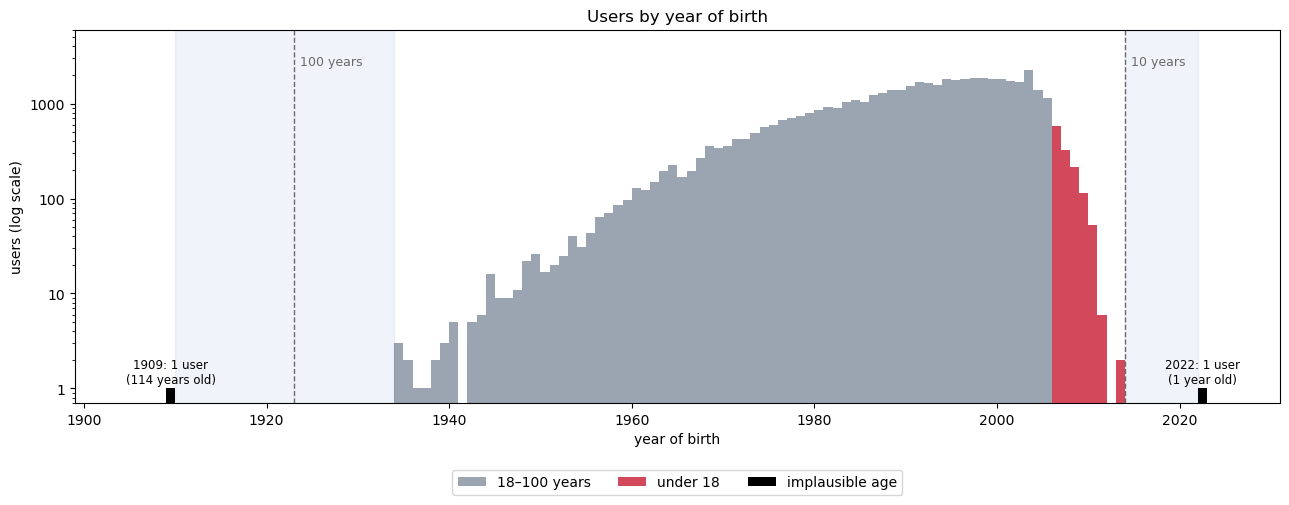

Implausible age: 2 
Under 18 (plausible age): 1285


In [24]:
REPORT_YEAR = 2023
AGE_MIN_PLAUSIBLE = 10
AGE_MAX_PLAUSIBLE = 100

age = REPORT_YEAR - details['year_birth']
implausible = ((age > AGE_MAX_PLAUSIBLE) | (age < AGE_MIN_PLAUSIBLE)).fillna(False)
minors = ((age < 18) & ~implausible).fillna(False)
known = details['year_birth'].notna()

fig, ax = plt.subplots(figsize=(13, 5.2))
bins = np.arange(1905, 2026, 1)
ax.hist(details.loc[known & ~implausible & ~minors, 'year_birth'].to_numpy(dtype=int), bins=bins, color='#9AA5B1', label='18–100 years')
ax.hist(details.loc[minors, 'year_birth'].to_numpy(dtype=int), bins=bins, color='#D1495B', label='under 18')
ax.hist(details.loc[implausible, 'year_birth'].to_numpy(dtype=int), bins=bins, color='black', label='implausible age')
ax.set_yscale('log')

# gaps in the distribution
for x0, x1 in [(1910, 1934), (2014, 2022)]:
    ax.axvspan(x0, x1, color='#2E5EAA', alpha=0.07)

# plausible age limits
for year, text in [(REPORT_YEAR - AGE_MAX_PLAUSIBLE, f'{AGE_MAX_PLAUSIBLE} years'),
                   (REPORT_YEAR - AGE_MIN_PLAUSIBLE + 1, f'{AGE_MIN_PLAUSIBLE} years')]:
    ax.axvline(year, ls='--', lw=1, color='dimgrey')
    ax.text(year + 0.7, 2500, text, fontsize=9, color='dimgrey')

for year, text, dy in [(1909, '1909: 1 user\n(114 years old)', 4), (2022, '2022: 1 user\n(1 year old)', 4)]:
    ax.annotate(text, (year + 0.5, years.get(year, 1)), xytext=(0, dy), textcoords='offset points',
                ha='center', fontsize=8.5)

ax.set_ylim(0.7, 6000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.0f}'.replace(',', ' ')))
ax.set_title('Users by year of birth')
ax.set_xlabel('year of birth'); ax.set_ylabel('users (log scale)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3)
plt.tight_layout()
plt.savefig('00_year_birth.png')
plt.show()

print(f'Implausible age: {implausible.sum()} \nUnder 18 (plausible age): {minors.sum()}')

2 suspicious records stand apart from the rest:
- 1909 (114 years old): the next year of birth in the data is 1934, 24 years apart;
- 2022 (1 year old): the previous year is 2013, with 8 empty years in between.

We set the plausible age range to 10–100 years. 1934 and 2013 are close to the bulk of the distribution and are not treated as outliers.

A separate problem: users under 18 (red bars). The service should register adults only.

## 4. Data preparation

In [25]:
df = summary.merge(details, on='user_reference', how='inner')

PASS_STATUSES = ['PASSED', 'APPROVED']
df['is_pass'] = df['decision_type'].isin(PASS_STATUSES)
df['country'] = df['data_issuing_country']
df['doc'] = df['data_type'].fillna('type not determined') + ' / ' + df['data_sub_type'].fillna('—')
df['week'] = df['date_'].dt.to_period('W-SUN').dt.start_time   # week starting Monday
df['age'] = REPORT_YEAR - df['year_birth']
print(f'Rows after join: {len(df)}')

Rows after join: 52075


In [26]:
def first_fail(row):
    '''First failed KYC check for a user who did not pass KYC.'''
    if row['is_pass']:
        return None
    for s in STAGES:
        if row[f'{s}_decision'] in ('REJECTED', 'WARNING'):
            return f"{s}:{row[f'{s}_decision']}"
    for s in STAGES:
        if row[f'{s}_decision'] == 'NOT_EXECUTED':
            return f'{s}:NOT_EXECUTED'
    return 'other'


DETAIL_COLS = {'usability': 'usability_decision_details', 'image_checks': 'image_checks_decision_details',
               'liveness': 'liveness_decision_details', 'similarity': 'similarity_decision_details'}

FAIL_GROUPS = {
    'image_checks:NOT_EXECUTED': 'Document not recognized',
    'image_checks:REJECTED':     'Suspected forgery',
    'usability:NOT_EXECUTED':    'Technical error',
    'similarity:REJECTED':       'Selfie does not match document',
    'similarity:WARNING':        'Selfie does not match document',
    'liveness:REJECTED':         'Liveness',
    'liveness:WARNING':          'Liveness',
}
# for usability (REJECTED and WARNING) one decision covers different problems, so the group is taken from the detail
USABILITY_GROUPS = {
    'UNSUPPORTED_DOCUMENT_TYPE':    'Unsupported document',
    'MISSING_MANDATORY_DATAPOINTS': 'Incomplete document',
    'MISSING_PAGE':                 'Incomplete document',
    'PART_OF_DOCUMENT_MISSING':     'Incomplete document',
    'PART_OF_DOCUMENT_HIDDEN':      'Incomplete document',
    'LIVENESS_UNDETERMINED':        'Liveness',
}   # other details (BLURRED, GLARE, DAMAGED_DOCUMENT, PHOTOCOPY, NOT_A_DOCUMENT) - photo quality

df['fail_stage'] = df.apply(first_fail, axis=1)
stage = df['fail_stage'].str.split(':').str[0]
df['detail'] = np.select([stage == s for s in DETAIL_COLS], [df[c] for c in DETAIL_COLS.values()], default=None)

df['fail_group'] = df['fail_stage'].map(FAIL_GROUPS)
is_usab = df['fail_stage'].isin(['usability:REJECTED', 'usability:WARNING'])
df.loc[is_usab, 'fail_group'] = df.loc[is_usab, 'detail'].map(USABILITY_GROUPS).fillna('Document photo quality')
df.loc[df['fail_stage'].notna() & df['fail_group'].isna(), 'fail_group'] = 'Other'

In [27]:
# Which stages fell into each reason group:
(df[df['fail_stage'].notna()]
   .groupby(['fail_group', 'fail_stage']).size()
   .rename('users').to_frame())

users
fail_group                     fail_stage                      
Document not recognized        image_checks:NOT_EXECUTED   1967
Document photo quality         usability:REJECTED           381
Incomplete document            usability:REJECTED           552
Liveness                       liveness:REJECTED            703
                               liveness:WARNING             131
                               usability:WARNING            277
Other                          data_checks:REJECTED           9
                               other                         17
Selfie does not match document similarity:REJECTED         1007
                               similarity:WARNING           346
Suspected forgery              image_checks:REJECTED        927
Technical error                usability:NOT_EXECUTED       420
Unsupported document           usability:WARNING            509

In [28]:
# How many non-passed users failed several checks at once
n_bad = df[[f'{s}_decision' for s in STAGES]].isin(['REJECTED', 'WARNING']).sum(axis=1)
print(f'Failed several checks at once: {(~df["is_pass"] & (n_bad >= 2)).sum()} of {(~df["is_pass"]).sum()}')

Failed several checks at once: 493 of 7246


493 non-passed users failed several checks at once; we take the first one in the chain as the reason. This is an assumption: the order of checks inside the vendor's system is not visible in the data.

In [29]:
# Check that a reason is assigned to all non-passed users and only to them:
pd.crosstab(df['is_pass'].map({True: 'passed', False: 'not passed'}),
            df['fail_group'].notna().map({True: 'has reason', False: 'no reason'}),
            margins=True)

fail_group,has reason,no reason,All
is_pass,,,
not passed,7246,0,7246
passed,0,44829,44829
All,7246,44829,52075


All 7 246 non-passed users have a reason, and passed users have none.

In [30]:
# Most users are in the "Document not recognized" group.
nr = df[df['fail_group'] == 'Document not recognized']
pd.concat({col: nr[col].fillna('empty').value_counts()
           for col in ['country', 'usability_decision', 'image_checks_decision_details', 'data_type']},
          names=['field', 'value']).rename('users').to_frame()

users
field                         value                            
country                       MEX                          1967
usability_decision            PASSED                       1967
image_checks_decision_details PRECONDITION_NOT_FULFILLED   1966
                              TECHNICAL_ERROR                 1
data_type                     empty                        1967

All 1 967 users in this group are from Mexico. Their photo is usable (usability PASSED), but the document type is empty: in 1 966 cases the detail is `PRECONDITION_NOT_FULFILLED`, meaning the vendor could not determine the document type.

## 5. Metric and overall dynamics
**Pass rate** = users with a final decision of PASSED or APPROVED / all users for whom the vendor made a decision, per day or week.

**Grain.** Outages last 1–2 days and get smeared out in weekly data, so they need to be looked for by day. A slow drift, on the contrary, can get lost in random daily noise.

We use the "before" period as the reference point: 25.07–13.08. It ends on 13.08 because in Mexico the decline already started in the week of 14.08 (see H3).

Day-to-day variation is 1.9 times the binomial. Noise: by day +/-2.9 p.p., by week +/-1.1 p.p.
Days in "before" outside the band: 1 of 20
Pass rate in "before" by weekday, %: {'Mon': 88.9, 'Tue': 89.3, 'Wed': 89.2, 'Thu': 88.8, 'Fri': 86.5, 'Sat': 88.7, 'Sun': 88.6}


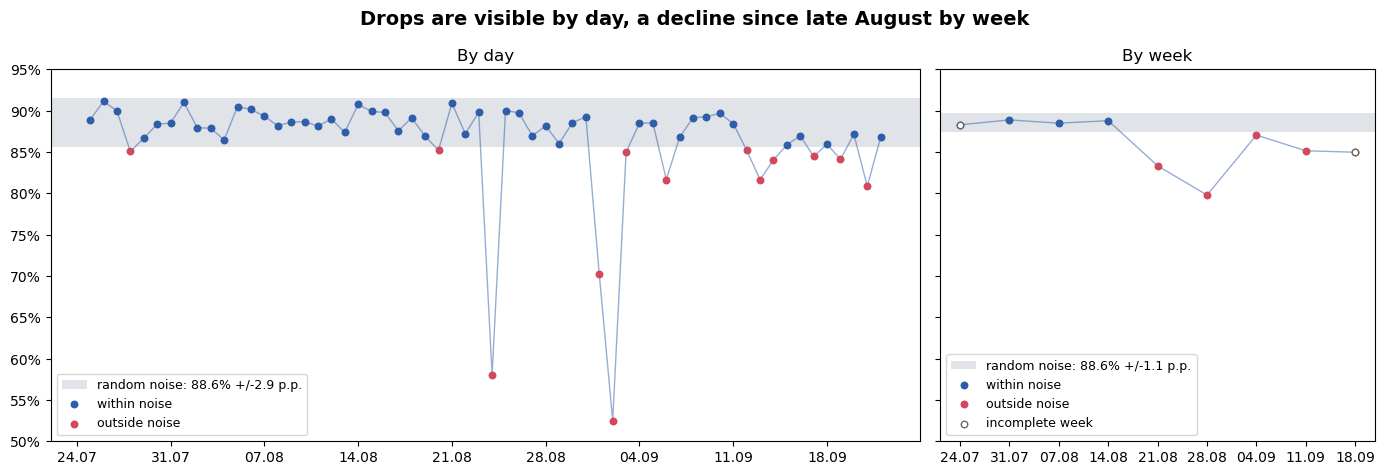

In [31]:
BASELINE_END = '2023-08-13'   # "before": the last day before the week when the decline in Mexico started

p0 = df.loc[df['date_'] <= BASELINE_END, 'is_pass'].mean()     # pass rate in the "before" period
daily_rate = df.groupby('date_')['is_pass'].agg(['mean', 'size'])
weekly_rate = df.groupby('week')['is_pass'].agg(['mean', 'size'])
weekly_rate['days'] = df.groupby('week')['date_'].nunique()

base_days = daily_rate[daily_rate.index <= BASELINE_END]
k = base_days['mean'].var() / (p0 * (1 - p0) / base_days['size']).mean()


def noise(n):
    '''Half-width of the 95% interval, adjusted for the actual day-to-day variation.'''
    return 1.96 * np.sqrt(k * p0 * (1 - p0) / n)


noise_day, noise_week = noise(daily_rate['size'].mean()), noise(weekly_rate['size'].mean())
print(f'Day-to-day variation is {k:.1f} times the binomial. Noise: by day +/-{noise_day * 100:.1f} p.p., by week +/-{noise_week * 100:.1f} p.p.')
print(f'Days in "before" outside the band: {((base_days["mean"] - p0).abs() > noise_day).sum()} of {len(base_days)}')
dow = df[df['date_'] <= BASELINE_END].groupby(df['date_'].dt.dayofweek)['is_pass'].mean().mul(100).round(1)
print('Pass rate in "before" by weekday, %:', dict(zip(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], dow)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True, gridspec_kw={'width_ratios': [2, 1]})
for ax, data, nz, title in [(ax1, daily_rate, noise_day, 'By day'), (ax2, weekly_rate, noise_week, 'By week')]:
    ax.axhspan(p0 - nz, p0 + nz, color='#9AA5B1', alpha=0.3, lw=0,
               label=f'random noise: {(p0 * 100):.1f}% +/-{(nz * 100):.1f} p.p.')
    outside = (data['mean'] - p0).abs() > nz
    ax.plot(data.index, data['mean'], color='#2E5EAA', lw=1, alpha=0.5)
    ax.scatter(data.index[~outside], data.loc[~outside, 'mean'], color='#2E5EAA', s=22, zorder=3, label='within noise')
    ax.scatter(data.index[outside], data.loc[outside, 'mean'], color='#D1495B', s=22, zorder=3, label='outside noise')
    ax.set_title(title)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
# incomplete weeks (first and last) — white dots
partial = weekly_rate['days'] < 7
ax2.scatter(weekly_rate.index[partial], weekly_rate.loc[partial, 'mean'], facecolor='white', edgecolor='dimgrey',
            s=22, zorder=4, label='incomplete week')
for ax in (ax1, ax2):
    ax.legend(loc='lower left', fontsize=9)
ax1.set_ylim(0.5, 0.95)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
fig.suptitle('Drops are visible by day, a decline since late August by week', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig('01a_noise_day_vs_week.png')
plt.show()

The grey band shows where 95% of values fall if the pass rate stays at the "before" level (88.6%).
By day, the drops on 24.08, 01–02.09 and 06.09 are far outside the band. By week, all weeks from 21.08 are below the band.
So we look for outages by day, and look at trends by country and reason by week.

In [32]:
daily = df.groupby('date_').agg(total=('is_pass', 'size'), pass_rate=('is_pass', 'mean'))
daily['traffic rank'] = daily['total'].rank(ascending=False).astype(int)

# Anomalous day: pass rate more than 5 p.p. below the median
ANOMALY_DROP = 0.05
median_rate = daily['pass_rate'].median()
anomaly_days = daily.index[daily['pass_rate'] < median_rate - ANOMALY_DROP]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
ax1.plot(daily.index, daily['pass_rate'], marker='o', ms=4, color='#2E5EAA')
ax1.axhline(median_rate, ls='--', color='#9AA5B1', lw=1, label=f'median {(median_rate * 100):.1f}%')
ax1.legend(loc='lower left')
for d in anomaly_days:
    ax1.annotate(f'{d:%d.%m}\n{daily.loc[d, "pass_rate"]:.0%}', (d, daily.loc[d, 'pass_rate']),
                 textcoords='offset points', xytext=(0, -32), ha='center', color='#D1495B', fontsize=9)

ax1.scatter(anomaly_days, daily.loc[anomaly_days, 'pass_rate'], color='#D1495B', zorder=3, s=40)
ax1.set_ylim(0.4, 1)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax1.set_title('KYC pass rate by day: sharp drops against a gradual decline')

ax2.bar(daily.index, daily['total'], color='#9AA5B1')
ax2.set_title('KYC decisions per day', fontsize=11)
ax2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))

plt.tight_layout()
plt.savefig('01_daily_pass_rate.png')
plt.show()

print('Anomalous days:\n', daily.loc[anomaly_days].round(3))

Anomalous days:
             total  pass_rate  traffic rank
date_                                     
2023-08-24   1193      0.580             4
2023-09-01   1157      0.702             6
2023-09-02    783      0.525            39
2023-09-06   1200      0.817             3
2023-09-13    741      0.816            46
2023-09-21    815      0.809            34


In [33]:
weekly = df.groupby('week').agg(days=('date_', 'nunique'), total=('is_pass', 'size'), pass_rate=('is_pass', 'mean'))
weekly['pass_rate'] = weekly['pass_rate'].mul(100).round(1)
weekly

,days,total,pass_rate
week,,,
2023-07-24,6,4816,88.3
2023-07-31,7,5863,88.9
2023-08-07,7,5966,88.5
2023-08-14,7,7359,88.8
2023-08-21,7,6417,83.3
2023-08-28,7,6185,79.8
2023-09-04,7,5636,87.0
2023-09-11,7,5594,85.1
2023-09-18,5,4239,85.0


- Six days with a drop: 24.08, 01.09, 02.09, 06.09, 13.09 and 21.09. Traffic on them differs: 24.08, 01.09 and 06.09 are among the busiest of the 60 days, the other days are normal.
- Besides the drops, the overall level is also declining: from ~88–89% in July–August to ~85% in the last weeks. The first and last weeks are incomplete.

These seem to be two different problems: one-off spikes in rejections and a gradual decline. Next we look at them separately.

## 6. Investigation: testing hypotheses

### H1. At which check stage do we lose users?
We look at how the weekly share of users screened out at each check changes.

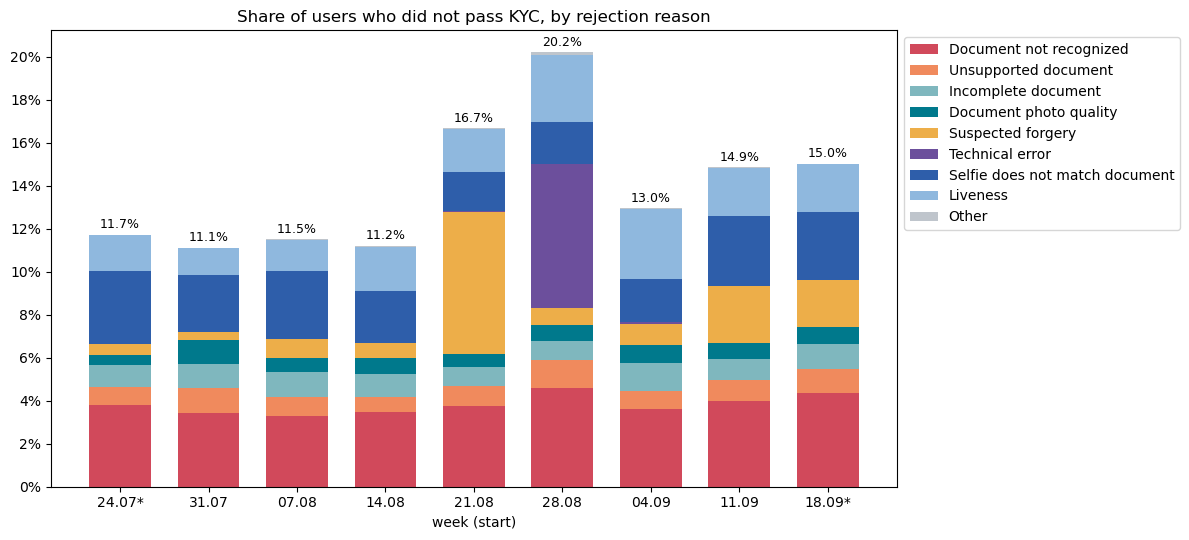

week,2023-07-24,2023-07-31,2023-08-07,2023-08-14,2023-08-21,2023-08-28,2023-09-04,2023-09-11,2023-09-18
fail_group,,,,,,,,,
Document not recognized,3.80,3.43,3.27,3.45,3.74,4.58,3.62,3.99,4.34
Unsupported document,0.85,1.18,0.91,0.71,0.97,1.29,0.85,0.97,1.16
Incomplete document,1.00,1.09,1.17,1.10,0.84,0.92,1.30,1.00,1.16
Document photo quality,0.48,1.11,0.62,0.73,0.61,0.71,0.82,0.73,0.75
Suspected forgery,0.50,0.41,0.92,0.69,6.64,0.82,0.99,2.63,2.19
Technical error,0.00,0.00,0.00,0.00,0.02,6.69,0.09,0.00,0.00
Selfie does not match document,3.43,2.61,3.13,2.42,1.84,1.96,2.00,3.27,3.18
Liveness,1.66,1.26,1.46,2.02,1.98,3.12,3.25,2.22,2.22
Other,0.00,0.03,0.03,0.08,0.05,0.11,0.04,0.05,0.02


In [34]:
reason_order = ['Document not recognized', 'Unsupported document', 'Incomplete document', 'Document photo quality',
                'Suspected forgery', 'Technical error', 'Selfie does not match document', 'Liveness', 'Other']

wk_reasons = (pd.crosstab(df['week'], df['fail_group'].fillna('Passed'), normalize='index')
                .drop(columns='Passed')[reason_order])

fig, ax = plt.subplots(figsize=(12, 5.5))
bottom = np.zeros(len(wk_reasons))
x = np.arange(len(wk_reasons))

REASON_COLORS = {
    'Document not recognized':           '#D1495B',
    'Unsupported document':       '#F08A5D',
    'Incomplete document':               '#7FB7BE',
    'Document photo quality':         '#00798C',
    'Suspected forgery':          '#EDAE49',
    'Technical error':              '#6C4F9C',
    'Selfie does not match document': '#2E5EAA',
    'Liveness':                        '#8FB8DE',
    'Other':                          '#BFC5CC',
    'One-off spikes':                '#3D3D3D',
}
for r in reason_order:
    ax.bar(x, wk_reasons[r], bottom=bottom, color=REASON_COLORS[r], label=r, width=0.7)
    bottom += wk_reasons[r].values
for i, v in enumerate(bottom):
    ax.text(i, v + 0.003, f'{v * 100:.1f}%', ha='center', fontsize=9)
ax.set_xticks(x, [f'{w:%d.%m}' + ('*' if weekly_rate.loc[w, 'days'] < 7 else '') for w in wk_reasons.index])
ax.set_xlabel('week (start)')
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.02))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title('Share of users who did not pass KYC, by rejection reason')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig('02_weekly_fail_reasons.png')
plt.show()

wk_reasons.mul(100).round(2).T

**H1 conclusion**
- Spikes in the week of 21.08 - "Suspected forgery", 28.08 - "Technical error" and Liveness, 04.09 - Liveness, 11.09 and 18.09 - "forgery" again.
- Without the spikes, "Document not recognized" and Liveness grew by September. "Selfie mismatch" dipped at the end of August and then returned to its previous level.
- The shares are calculated for both countries together, but "Document not recognized" occurs only in Mexico. So we will look at the countries separately later.

### H2. Are the drops caused by vendor outages?
If a drop is caused by an outage, one specific rejection reason should rise sharply on that day. For each drop day, let's see which reasons grew the most compared to the "before" period.

In [35]:
fails = df[~df['is_pass']]
reason_day = pd.crosstab(fails['date_'], fails['detail'].fillna('—') + ' (' + fails['fail_stage'].str.split(':').str[0] + ')')
reason_rate = reason_day.div(daily['total'], axis=0)          # share of all checks that day
base_rate = reason_rate.loc[:BASELINE_END].mean()           # usual share in "before"

rows = []
for d in anomaly_days:
    extra = ((reason_rate.loc[d] - base_rate) * daily.loc[d, 'total']).sort_values(ascending=False)
    rows.append({'day': f'{d:%d.%m}', 'pass rate, %': round(daily.loc[d, 'pass_rate'] * 100, 1),
                 'traffic rank': daily.loc[d, 'traffic rank'],
                 'reason 1': extra.index[0], 'rejections 1': round(extra.iloc[0]),
                 'reason 2': extra.index[1], 'rejections 2': round(extra.iloc[1])})
pd.DataFrame(rows).set_index('day')

,"pass rate, %",traffic rank,reason 1,rejections 1,reason 2,rejections 2
day,,,,,,
24.08,58.0,4,MANIPULATED_DOCUMENT (image_checks),376,PRECONDITION_NOT_FULFILLED (image_checks),9
01.09,70.2,6,TECHNICAL_ERROR (usability),171,BAD_QUALITY (liveness),63
02.09,52.5,39,TECHNICAL_ERROR (usability),236,PRECONDITION_NOT_FULFILLED (image_checks),36
06.09,81.7,3,BAD_QUALITY (liveness),59,FACE_NOT_FULLY_VISIBLE (liveness),24
13.09,81.6,46,LIVENESS_UNDETERMINED (liveness),20,NO_MATCH (similarity),18
21.09,80.9,34,LIVENESS_UNDETERMINED (liveness),12,PRECONDITION_NOT_FULFILLED (image_checks),11


- On 24.08 almost all rejections are `MANIPULATED_DOCUMENT`: the anti-fraud check flagged documents as tampered with.
- On 01–02.09 `TECHNICAL_ERROR` on usability: the check did not run. On 01.09 liveness `BAD_QUALITY` rejections grew at the same time.
- On 06.09 the same rise in liveness `BAD_QUALITY` and `FACE_NOT_FULLY_VISIBLE` as on 01.09.
- On 13.09 and 21.09 there is no single reason that rose sharply.

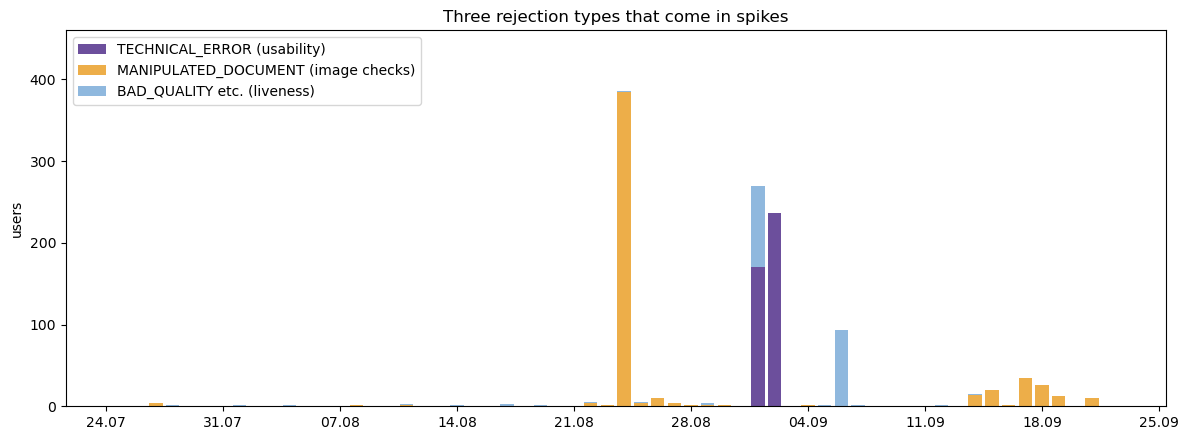

In [36]:
df['tech_error'] = df['usability_decision_details'] == 'TECHNICAL_ERROR'
df['manipulated'] = df['image_checks_decision_details'] == 'MANIPULATED_DOCUMENT'
df['bad_selfie'] = df['liveness_decision_details'].isin(['BAD_QUALITY', 'FACE_NOT_FULLY_VISIBLE', 'ID_USED_AS_SELFIE'])
by_day = df.groupby('date_')[['tech_error', 'manipulated', 'bad_selfie']].sum()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(by_day.index, by_day['tech_error'], color=REASON_COLORS['Technical error'], label='TECHNICAL_ERROR (usability)')
ax.bar(by_day.index, by_day['manipulated'], bottom=by_day['tech_error'],
       color=REASON_COLORS['Suspected forgery'], label='MANIPULATED_DOCUMENT (image checks)')
ax.bar(by_day.index, by_day['bad_selfie'], bottom=by_day['tech_error'] + by_day['manipulated'],
       color=REASON_COLORS['Liveness'], label='BAD_QUALITY etc. (liveness)')
ax.set_ylim(0, 460); ax.set_ylabel('users')
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
ax.legend(loc='upper left')
ax.set_title('Three rejection types that come in spikes')
plt.tight_layout()
plt.savefig('03_incident_spikes.png')
plt.show()

The chart shows one more spike on 14–19.09: `MANIPULATED_DOCUMENT` again, but weaker.

In [37]:
sep = df[df['date_'] >= '2023-09-11']
pd.crosstab(sep.loc[sep['manipulated'], 'country'], sep.loc[sep['manipulated'], 'doc'], margins=True)

doc,ID_CARD / ELECTORAL_ID,ID_CARD / NATIONAL_ID,All
country,,,
ARG,0,12,12
MEX,106,0,106
All,106,12,118


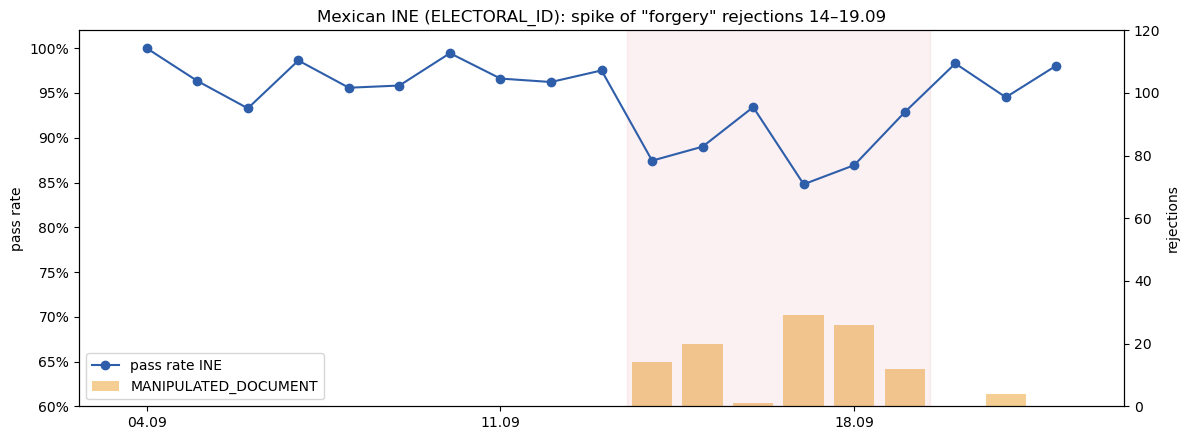

In [38]:
is_ine = (df['country'] == 'MEX') & (df['data_sub_type'] == 'ELECTORAL_ID')
ine = df[is_ine & (df['date_'] >= '2023-09-04')].groupby('date_').agg(
    pass_rate=('is_pass', 'mean'), manipulated=('manipulated', 'sum'))

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.axvspan(pd.Timestamp('2023-09-13 12:00'), pd.Timestamp('2023-09-19 12:00'), color='#D1495B', alpha=0.08)
ax1.plot(ine.index, ine['pass_rate'], marker='o', color='#2E5EAA', label='pass rate INE')
ax1.set_ylim(0.6, 1.02)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax1.set_ylabel('pass rate')

ax2 = ax1.twinx()
ax2.bar(ine.index, ine['manipulated'], color=REASON_COLORS['Suspected forgery'], alpha=0.6, label='MANIPULATED_DOCUMENT')
ax2.set_ylim(0, 120); ax2.set_ylabel('rejections'); ax2.grid(False); ax2.spines['right'].set_visible(True)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='lower left')
ax1.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
ax1.set_title('Mexican INE (ELECTORAL_ID): spike of "forgery" rejections 14–19.09')
plt.tight_layout()
plt.savefig('04_ine_episode.png')
plt.show()

The episode affected almost only the Mexican INE. From 20.09 the INE pass rate is again around 97%, as before the spike, but there are only 3 days of data after the spike.

In [39]:
day = df[df['date_'] == '2023-08-24']
pd.crosstab(day.loc[day['manipulated'], 'country'], day.loc[day['manipulated'], 'doc'], margins=True)

doc,DRIVING_LICENSE / REGULAR_DRIVING_LICENSE,ID_CARD / NATIONAL_ID,PASSPORT / —,All
country,,,,
ARG,33,350,0,383
MEX,0,0,1,1
All,33,350,1,384


In [40]:
# The "forgeries" on 24.08 are almost all from Argentina. Compare this day with other Thursdays.
arg_thu = df[(df['country'] == 'ARG') & (df['date_'].dt.dayofweek == 3)]
(arg_thu.groupby('date_')
        .agg(checks=('is_pass', 'size'), not_flagged=('manipulated', lambda s: (~s).sum()), passed=('is_pass', 'sum'))
        .rename(index=lambda d: f'{d:%d.%m}').T)

date_,27.07,03.08,10.08,17.08,24.08,31.08,07.09,14.09,21.09
checks,283,335,330,718,660,304,320,512,341
not_flagged,283,335,330,718,277,304,320,512,335
passed,273,312,319,680,265,294,304,484,295


On 24.08 Argentina had 660 checks, while on other Thursdays it usually has 280–340. Without those flagged `MANIPULATED_DOCUMENT`, 277 remain, and 265 of them passed. It looks like the 383 people with "forgeries" came on top of normal traffic. This could be either a wave of real forgeries or an anti-fraud error on new traffic: the data cannot tell them apart.

Let's flag the users rejected during the spikes and count them.

In [41]:
df['incident'] = np.select(
    [(df['date_'] == '2023-08-24') & df['manipulated'],
     df['date_'].isin(pd.to_datetime(['2023-09-01', '2023-09-02'])) & df['tech_error'],
     df['date_'].isin(pd.to_datetime(['2023-09-01', '2023-09-06'])) & df['bad_selfie'],
     df['date_'].between('2023-09-14', '2023-09-19') & is_ine & df['manipulated']],
    ['24.08 forgery', '01–02.09 technical error', '01.09 and 06.09 liveness', '14–19.09 forgery INE'],
    default='')
df['reason'] = np.where(df['incident'] != '', 'One-off spikes', df['fail_group'])

inc = (df[df['incident'] != ''].groupby('incident')
         .agg(rejected=('user_reference', 'size'), MEX=('country', lambda s: (s == 'MEX').sum()),
              ARG=('country', lambda s: (s == 'ARG').sum())))
inc.loc['Total'] = inc.sum()
print(f'Did not pass KYC in the period: {(~df["is_pass"]).sum()}; of them in spikes: {inc.loc["Total", "rejected"]} '
      f'({inc.loc["Total", "rejected"] / (~df["is_pass"]).sum():.0%})')
inc

Did not pass KYC in the period: 7246; of them in spikes: 1085 (15%)


,rejected,MEX,ARG
incident,,,
01.09 and 06.09 liveness,192,96,96
01–02.09 technical error,407,262,145
14–19.09 forgery INE,102,102,0
24.08 forgery,384,1,383
Total,1085,461,624


**H2 conclusion:** the hypothesis is partly confirmed. The drops come from short spikes of rejections of a single type: 1 085 users (15% of all rejections) were rejected in 4 spikes. But the data does not prove that this is specifically a vendor outage:
- 24.08 may also be a wave of real forgeries
- `TECHNICAL_ERROR` and liveness `BAD_QUALITY` occur during photo upload, so the problem may also be on our side.

There are no public reports of vendor outages on these dates. We need confirmation from the vendor and a check of our releases on these days.

The spikes explain the drops but not the overall decline, so from here on we exclude spike users from the trends.

### H3. Has the traffic mix changed?
The data has two countries with different pass rates. If the share of the "harder" country grew, the overall pass rate will fall even if nothing changed within the countries (mix shift). Let's check the country shares and the pass rate within each.

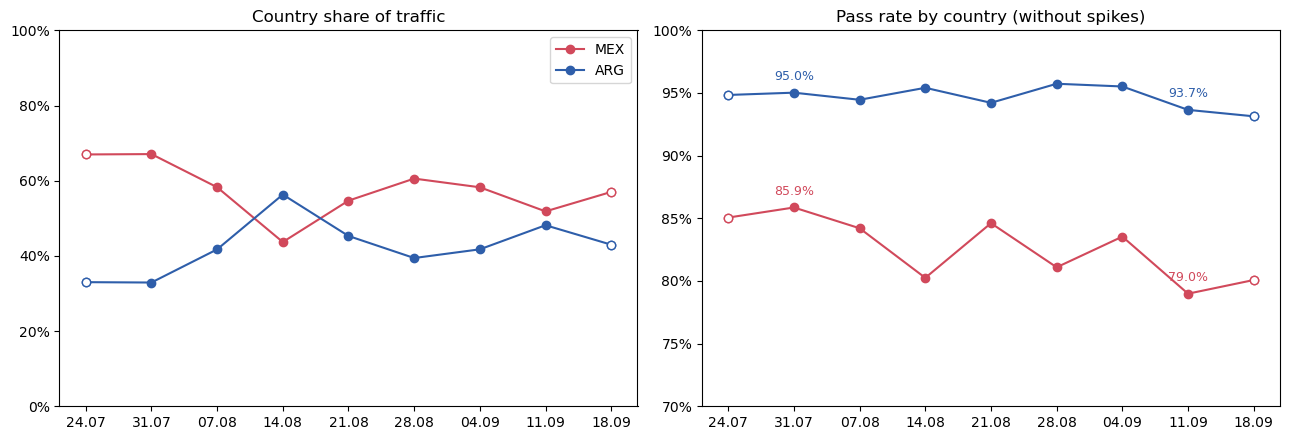

In [42]:
clean = df[df['incident'] == '']   # without users rejected during the spikes

share = pd.crosstab(df['week'], df['country'], normalize='index')
rate = clean.pivot_table(index='week', columns='country', values='is_pass', aggfunc='mean')
full_weeks = weekly_rate.index[weekly_rate['days'] == 7]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
COLORS = {'MEX': '#D1495B', 'ARG': '#2E5EAA'}
for c in ['MEX', 'ARG']:
    ax1.plot(share.index, share[c], marker='o', color=COLORS[c], label=c)
    ax2.plot(rate.index, rate[c], marker='o', color=COLORS[c], label=c)
    for ax, data in [(ax1, share), (ax2, rate)]:   # incomplete weeks — white dots
        ax.scatter(data.index[partial], data.loc[partial, c], facecolor='white', edgecolor=COLORS[c], zorder=3)
    for w in (full_weeks[0], full_weeks[-1]):
        ax2.annotate(f'{(rate.loc[w, c] * 100):.1f}%', (w, rate.loc[w, c]),
                     xytext=(0, 9), textcoords='offset points', ha='center', color=COLORS[c], fontsize=9)
ax1.set_ylim(0, 1)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax1.set_title('Country share of traffic'); ax1.legend()
ax2.set_ylim(0.7, 1)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax2.set_title('Pass rate by country (without spikes)')
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
plt.tight_layout()
plt.savefig('05_country_mix_vs_rate.png')
plt.show()

Argentina's share jumps between 33% and 56%. In the week of 14.08 Mexico's pass rate had already fallen to 80%, but the overall rate stayed at 88.8% because Argentina's share rose to 56%. That is why the "before" period ends on 13.08.

Let's compare the "before" (25.07–13.08) and "now" (11–22.09) windows.

In [43]:
RECENT_START = '2023-09-11'   # "now": the last two weeks of data

win = np.select([df['date_'] <= BASELINE_END, df['date_'] >= RECENT_START], ['before', 'now'], default=None)
df['window'] = win
clean = df[df['incident'] == '']


def diff_ci(data, col, n_boot=2000, seed=0):
    '''95% interval for the difference "now" − "before".'''
    rng = np.random.default_rng(seed)
    days = {w: data[data['window'] == w].groupby('date_')[col].agg(['sum', 'size']).to_numpy() for w in ['before', 'now']}
    diffs = []
    for _ in range(n_boot):
        s = {w: a[rng.integers(0, len(a), len(a))].sum(axis=0) for w, a in days.items()}
        diffs.append(s['now'][0] / s['now'][1] - s['before'][0] / s['before'][1])
    return np.percentile(diffs, [2.5, 97.5])


cmp_country = pd.concat({
    'traffic share, %': pd.crosstab(df['country'], df['window'], normalize='columns').mul(100),
    'pass rate without spikes, %': clean.pivot_table(index='country', columns='window', values='is_pass', aggfunc='mean').mul(100),
}, axis=1).round(1)
cmp_country[('pass rate without spikes, %', 'change')] = (cmp_country[('pass rate without spikes, %', 'now')]
                                                           - cmp_country[('pass rate without spikes, %', 'before')]).round(1)
cmp_country[('pass rate without spikes, %', '95% interval')] = [
    '[{:+.1f}; {:+.1f}]'.format(*diff_ci(clean[clean['country'] == c], 'is_pass') * 100) for c in cmp_country.index]
cmp_country

traffic share, %       pass rate without spikes, %               \
window            before   now                      before   now change   
country                                                                   
ARG                 36.1  45.9                        94.7  93.4   -1.3   
MEX                 63.9  54.1                        85.1  79.5   -5.6   

                       
window   95% interval  
country                
ARG      [-3.1; +0.3]  
MEX      [-7.6; -3.7]

**H3 conclusion:** the hypothesis is rejected. The share of Argentina, where the pass rate is higher, grew from 36% to 46%, so the traffic mix rather supports the overall rate. The drop happens within Mexico: the pass rate without spikes fell from 85.1% to 79.5% (−5.6 p.p.). In Argentina it is −1.3 p.p., but this is within random variation.

### H4. What is falling in Mexico?
Let's compare rejection reasons for Mexican users "before" and "now", without spike users.

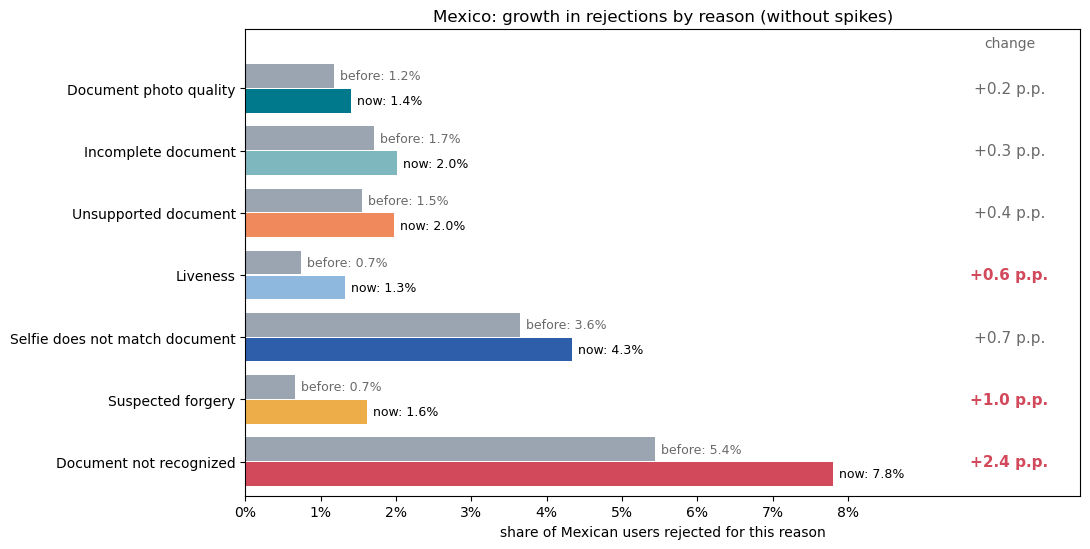

window,before,now,"change, p.p.",95% interval,significant
fail_group,,,,,
Document photo quality,1.18,1.40,0.22,[-0.2; +0.7],False
Incomplete document,1.71,2.01,0.30,[-0.3; +1.0],False
Unsupported document,1.54,1.98,0.43,[-0.1; +1.0],False
Liveness,0.73,1.32,0.59,[+0.1; +1.1],True
Selfie does not match document,3.65,4.33,0.69,[-0.3; +1.8],False
Suspected forgery,0.66,1.61,0.95,[+0.1; +1.9],True
Document not recognized,5.44,7.80,2.36,[+1.6; +3.2],True


In [44]:
mex = clean[(clean['country'] == 'MEX') & clean['window'].notna()]
mex_cmp = (pd.crosstab(mex['fail_group'].fillna('Passed'), mex['window'], normalize='columns')
             .drop(index='Passed').mul(100))
mex_cmp['change, p.p.'] = mex_cmp['now'] - mex_cmp['before']
mex_cmp = mex_cmp.sort_values('change, p.p.')
mex_cmp = mex_cmp[mex_cmp[['before', 'now']].max(axis=1) >= 0.1]   # without rare reasons (<0.1%)
ci = {r: diff_ci(mex.assign(flag=mex['fail_group'] == r), 'flag') * 100 for r in mex_cmp.index}
mex_cmp['95% interval'] = [f'[{ci[r][0]:+.1f}; {ci[r][1]:+.1f}]' for r in mex_cmp.index]
mex_cmp['significant'] = [(ci[r][0] > 0) | (ci[r][1] < 0) for r in mex_cmp.index]

fig, ax = plt.subplots(figsize=(11, 5.6))
y = np.arange(len(mex_cmp))
x_max = mex_cmp[['before', 'now']].values.max()
x_delta = x_max * 1.30          # change column on the right

ax.barh(y - 0.2, mex_cmp['before'], height=0.38, color='#9AA5B1')
ax.barh(y + 0.2, mex_cmp['now'], height=0.38, color=[REASON_COLORS[r] for r in mex_cmp.index])
for i, (r, row) in enumerate(mex_cmp.iterrows()):
    # period labels right next to the bars instead of a legend
    ax.text(row['before'] + 0.08, i - 0.2, f"before: {(row['before']):.1f}%", va='center', fontsize=9, color='dimgrey')
    ax.text(row['now'] + 0.08, i + 0.2, f"now: {(row['now']):.1f}%", va='center', fontsize=9, color='black')
    d = row['change, p.p.']
    ax.text(x_delta, i, ('+' if d >= 0 else '−') + f"{abs(d):.1f} p.p.", va='center', ha='center', fontsize=11,
            fontweight='bold' if row['significant'] else 'normal', color='#D1495B' if row['significant'] else 'dimgrey')
ax.text(x_delta, -0.62, 'change', ha='center', va='bottom', fontsize=10, color='dimgrey')
ax.set_yticks(y, mex_cmp.index)
ax.set_ylim(len(mex_cmp) - 0.45, -0.95)   # space at the top for the column label
ax.set_xlim(0, x_max * 1.42)
ax.set_xticks(np.arange(0, np.ceil(x_max) + 1, 1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
ax.set_xlabel('share of Mexican users rejected for this reason')
ax.set_title('Mexico: growth in rejections by reason (without spikes)')
plt.tight_layout()
plt.savefig('06_mex_reasons.png')
plt.show()

mex_cmp.round(2)

In [45]:
# Who falls into "Document not recognized"
nr = df[df['fail_group'] == 'Document not recognized']
print('Country:', nr['country'].value_counts().to_dict())
print('Usability decision:', nr['usability_decision'].value_counts().to_dict())
print('Detail:', nr['image_checks_decision_details'].value_counts().to_dict())
print(f'Average per day: {nr.groupby("date_").size().mean():.0f} users')

Country: {'MEX': 1967}
Usability decision: {'PASSED': 1967}
Detail: {'PRECONDITION_NOT_FULFILLED': 1966, 'TECHNICAL_ERROR': 1}
Average per day: 33 users


In [46]:
# Document types in Mexico: share of traffic and pass rate (without spikes)
mex_all = df[(df['country'] == 'MEX') & df['window'].notna()]
mex_docs = pd.concat({
    'share, %': pd.crosstab(mex_all['doc'], mex_all['window'], normalize='columns').mul(100),
    'pass rate, %': mex.pivot_table(index='doc', columns='window', values='is_pass', aggfunc='mean').mul(100),
}, axis=1).round(1)
mex_docs[mex_docs[('share, %', 'before')] >= 1].sort_values(('share, %', 'before'), ascending=False)

share, %       pass rate, %      
window                         before   now       before   now
doc                                                           
ID_CARD / ELECTORAL_ID           40.1  40.1         97.9  97.0
ID_CARD / NATIONAL_ID            39.2  34.0         91.0  87.8
type not determined / —          10.4  14.7          0.0   0.9
PASSPORT / —                      6.3   6.4         98.4  97.3
ID_CARD / RESIDENT_PERMIT_ID      2.9   3.8         97.1  98.0

In [47]:
# share of all Mexican users, %
fake = mex[mex['fail_group'] == 'Suspected forgery']
(pd.crosstab(fake['detail'], fake['window']) / mex['window'].value_counts() * 100).round(2).sort_values('now', ascending=False).head(5)

window,before,now
detail,,
DIGITAL_COPY,0.39,1.27
MANIPULATED_DOCUMENT_PHOTO,0.05,0.15
MANIPULATED_DOCUMENT,0.07,0.08
OTHER_REJECTION,0.03,0.08
MANIPULATED_DOCUMENT_SECURITY_CHECKS,0.00,0.02


**H4 conclusion.** Without the spikes, rejections in Mexico grew by 5.6 p.p. Three reasons grew more than random variation:
- "Document not recognized": +2.4 p.p., the largest. These users' photos are usable, but the vendor did not determine the document type. At the same time, the share of ID_CARD / NATIONAL_ID in Mexico fell from 39% to 34%, and its pass rate fell from 91% to 88%. It is worth finding out from the vendor which Mexican documents it does not recognize.
- "Suspected forgery": +1.0 p.p. Almost all the growth is in `DIGITAL_COPY`: a photo of a screen or a scan instead of the original.
- Liveness: +0.6 p.p.

The other reasons grew within random variation. So the issue is not that users started photographing their documents worse. Whether the growth is related to changes on our side cannot be checked with this data.

### Summary: decomposition of the pass rate drop

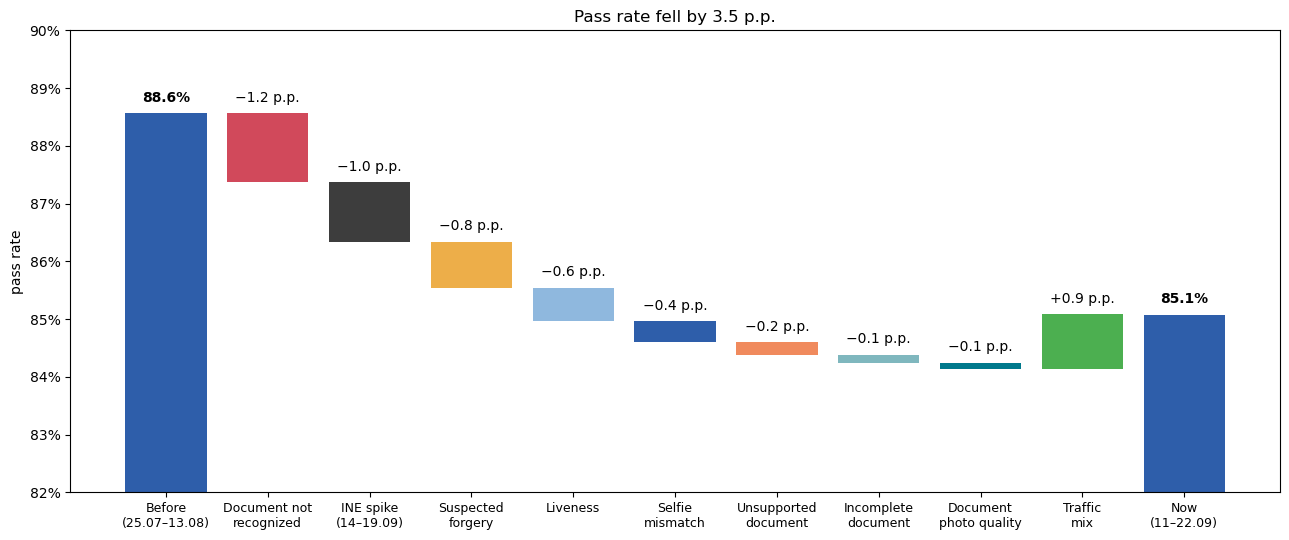

,"contribution, p.p."
Document not recognized,-1.20
One-off spikes,-1.04
Suspected forgery,-0.80
Liveness,-0.57
Selfie does not match document,-0.37
Unsupported document,-0.21
Incomplete document,-0.14
Document photo quality,-0.11
Traffic mix,0.95


In [48]:
def decompose(b, r_):
    '''Contribution of the traffic mix and rejection reasons (by country) to the pass rate change between windows b and r_.'''
    p_b, p_r = b['is_pass'].mean(), r_['is_pass'].mean()
    w_b, w_r = b['country'].value_counts(normalize=True), r_['country'].value_counts(normalize=True)
    mix = ((w_r - w_b) * b.groupby('country')['is_pass'].mean()).sum()
    s_b = pd.crosstab(b['country'], b['reason'].fillna('Passed'), normalize='index')
    s_r = pd.crosstab(r_['country'], r_['reason'].fillna('Passed'), normalize='index')
    s_b, s_r = s_b.align(s_r, fill_value=0)
    within = (-(s_r - s_b).mul(w_r, axis=0)).drop(columns='Passed')   # rows — countries, columns — reasons
    return p_b, p_r, mix, within


b, r_ = df[df['window'] == 'before'], df[df['window'] == 'now']
p_b, p_r, mix, within_by_country = decompose(b, r_)
within = within_by_country.sum()

bridge = pd.concat([pd.Series({'Traffic mix': mix}), within]).sort_values()
bridge = bridge[bridge.abs() >= 0.0005]
assert abs(bridge.sum() - (p_r - p_b)) < 0.001, 'decomposition does not add up'

# Waterfall
WRAP = {'Document not recognized': 'Document not\nrecognized', 'Unsupported document': 'Unsupported\ndocument',
        'Incomplete document': 'Incomplete\ndocument', 'Suspected forgery': 'Suspected\nforgery',
        'Document photo quality': 'Document\nphoto quality', 'Selfie does not match document': 'Selfie\nmismatch',
        'Technical error': 'Technical\nerror', 'One-off spikes': 'INE spike\n(14–19.09)',
        'Traffic mix': 'Traffic\nmix'}
labels = ['Before\n(25.07–13.08)'] + [WRAP.get(l, l) for l in bridge.index] + ['Now\n(11–22.09)']
vals = [p_b] + list(bridge.values) + [p_r]
levels = p_b + np.cumsum(np.r_[0, bridge.values])
fig, ax = plt.subplots(figsize=(13, 5.5))
cum = p_b
for i, v in enumerate(vals):
    if i in (0, len(vals) - 1):
        ax.bar(i, v, color='#2E5EAA'); ax.text(i, v + 0.002, f'{(v * 100):.1f}%', ha='center', fontweight='bold')
    else:
        name = bridge.index[i - 1]
        color = REASON_COLORS.get(name, '#9AA5B1') if v < 0 else '#4CAF50'
        ax.bar(i, v, bottom=cum, color=color)
        ax.text(i, max(cum, cum + v) + 0.002, ('+' if v > 0 else '−') + f'{(abs(v) * 100):.1f} p.p.', ha='center', fontsize=10)
        cum += v
ax.set_xticks(range(len(vals)), labels, fontsize=9)
ax.set_ylim(np.floor(levels.min() * 100 - 2) / 100, np.ceil(levels.max() * 100 + 1) / 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylabel('pass rate')
ax.set_title(f'Pass rate fell by {(abs(p_r - p_b) * 100):.1f} p.p.')
plt.tight_layout()
plt.savefig('07_bridge.png')
plt.show()

(bridge * 100).round(2).rename('contribution, p.p.').to_frame()

In [49]:
# Contribution of reasons by country, p.p.
by_country = within_by_country.T.mul(100)
by_country.loc['Total'] = by_country.sum()
by_country.round(2)

country,ARG,MEX
reason,,
Document not recognized,-0.00,-1.20
Document photo quality,-0.00,-0.11
Incomplete document,-0.00,-0.14
Liveness,-0.27,-0.31
One-off spikes,-0.00,-1.04
Other,0.01,-0.03
Selfie does not match document,-0.04,-0.33
Suspected forgery,-0.30,-0.50
Unsupported document,-0.00,-0.21


**Conclusion.** Of the −3.5 p.p. drop:
- −1.0 p.p. comes from the Mexican INE spike on 14–19.09, which fell into the "now" window;
- −3.4 p.p. comes from deterioration within countries. Of this, −2.8 p.p. is in Mexico and −0.6 p.p. in Argentina;
- +0.9 p.p. comes from the traffic mix (Argentina's share grew).

Without the spikes, the pass rate would have fallen by about 2.5 p.p.

## 7. Data and compliance

In [50]:
passed = df[df['is_pass']]

minors_passed = passed[(passed['age'] < 18).fillna(False)]
print(f'Users under 18 who passed KYC: {len(minors_passed)}')
print('By country:', minors_passed['country'].value_counts().to_dict())
print('By document:', minors_passed['doc'].value_counts().head(3).to_dict())
print('By age (years: users):', ', '.join(f'{k}: {v}' for k, v in minors_passed['age'].value_counts().sort_index().items()))
print(f'Passed with year of birth 2005 (calculated age 18, some were still 17 on the check date): {(passed["year_birth"] == 2005).sum()}')
print(f'Passed without year of birth: {passed["year_birth"].isna().sum()}, without document type: {passed["data_type"].isna().sum()}')
bad_age = ((df['age'] < AGE_MIN_PLAUSIBLE) | (df['age'] > AGE_MAX_PLAUSIBLE)).fillna(False)
print(f'Implausible age: {bad_age.sum()}, of them passed KYC: {(bad_age & df["is_pass"]).sum()}')

print('\nSanctions list screening among passed users:', passed['watchlist_screening_decision'].fillna('empty').value_counts().to_dict())
no_watchlist = passed[passed['watchlist_screening_decision'].isna()]
print('No screening result, most frequent dates:', no_watchlist['date_'].dt.strftime('%d.%m').value_counts().head(4).to_dict())
print('No screening result, final status:', no_watchlist['decision_type'].value_counts().to_dict())

print('\nPassed although a check failed or did not run:')
for s in STAGES[:-1]:
    not_ok = passed[f'{s}_decision'] != 'PASSED'
    if not_ok.any():
        print(f'  {s}: {passed.loc[not_ok, f"{s}_decision"].value_counts().to_dict()}')
not_run = passed[passed['usability_decision'] == 'NOT_EXECUTED']
print('usability NOT_EXECUTED among passed users, details:', not_run['usability_decision_details'].value_counts().to_dict(),
      '| dates:', not_run['date_'].dt.strftime('%d.%m').value_counts().to_dict())

Users under 18 who passed KYC: 1223
By country: {'ARG': 1152, 'MEX': 71}
By document: {'ID_CARD / NATIONAL_ID': 1159, 'PASSPORT / —': 45, 'DRIVING_LICENSE / REGULAR_DRIVING_LICENSE': 14}
By age (years: users): 10: 1, 12: 5, 13: 52, 14: 108, 15: 205, 16: 310, 17: 542
Passed with year of birth 2005 (calculated age 18, some were still 17 on the check date): 1071
Passed without year of birth: 20, without document type: 19
Implausible age: 2, of them passed KYC: 0

Sanctions list screening among passed users: {'PASSED': 44674, 'empty': 85, 'WARNING': 69, 'NOT_EXECUTED': 1}
No screening result, most frequent dates: {'24.08': 18, '30.08': 8, '01.09': 6, '25.08': 5}
No screening result, final status: {'PASSED': 81, 'APPROVED': 4}

Passed although a check failed or did not run:
  usability: {'NOT_EXECUTED': 201, 'WARNING': 1}
  liveness: {'REJECTED': 2}
  similarity: {'REJECTED': 1}
usability NOT_EXECUTED among passed users, details: {'NOT_UPLOADED': 201} | dates: {'01.09': 119, '06.09': 81, '2

- The service registers only users over 18, but KYC does not check this rule: 1 223 minors passed the procedure, 94% of them in Argentina. This is a lower bound: age is known only from the year, and some of the 1 071 passed users born in 2005 were not yet 18 on the check date. 20 passed users have no year of birth, so their age cannot be checked.
- 69 users passed KYC with WARNING in the sanctions list screening, 1 - with NOT_EXECUTED, 85 have no result. Empty results are most common at the end of August, and they include all 4 APPROVED and all 8 rows with `OK`. It looks like a separate process, for example a manual review. We need to find out from compliance and the vendor whether this is acceptable.
- 201 users passed KYC even though the usability check did not run (`NOT_UPLOADED`). Almost all of them were on 01.09 and 06.09, the days of the liveness rejection spike.
- 3 users passed KYC with REJECTED in liveness or similarity, and only one of them is visible from the final statuses (section 3.4). If this is a manual approval, it should be marked with a separate status.
- Years of birth 1909 and 2022 are most likely data extraction errors. Both users were rejected.
- Statuses contain non-standard values (`PASSES`, `OK`). The pipeline needs normalization.

## 8. Conclusions
1. The pass rate drop is made up of two problems: one-off spikes in rejections (4 episodes, 1 085 users, 15% of all rejections) and a gradual deterioration in Mexico that started in mid-August. The cause of the spikes needs to be confirmed with the vendor and checked against our releases.
2. The main reason for the decline in Mexico is "Document not recognized": the photo is usable, but the vendor does not determine the document type. Next come digital copies instead of a photo of the original, and liveness. Document photo quality has barely changed.
3. The traffic mix does not explain the drop: Argentina's share grew, and this rather supported the rate.
4. Compliance: at least 1 223 minors passed KYC, as well as 69 people with WARNING in the sanctions screening, 86 without a result for this check, and 201 without the usability check.